# 03 · 모델링 — Baseline: Scratch / Feature Extraction / Fine-tuning

같은 ResNet18을 세 가지 방식으로 학습해 비교합니다. 이 노트북의 목표는 **공정한 비교 기준선(baseline)**을 만드는 것이며, 성능 개선은 Val 오분류 분석 이후 별도 실험으로 진행합니다.

**02_preprocessing에서 확정해 그대로 쓰는 것** (`src/common.py`에서 불러옴)

| 항목 | 내용 |
|---|---|
| 분할 | 제공된 Train 640 / Val 160 / Test 1,231 그대로 |
| 입력 | 224×224, 비율 유지 Resize(긴 변 224) + ImageNet 평균색 (124, 116, 104) Padding |
| 정규화 | ImageNet 평균·표준편차 (`IMAGENET1K_V1`) |
| Train 증강 | 없음 (baseline) / Val·Test는 고정 전처리 |
| Batch · Seed | 32 · 42, `num_workers=0` |
| 지표 | Val Macro F1 (Accuracy, 클래스별 Precision·Recall·F1, Confusion Matrix 함께 확인) |

**이 노트북에서 정한 학습 조건**

| 항목 | Scratch | Feature Extraction | Fine-tuning |
|---|---|---|---|
| 초기 가중치 | 무작위 | IMAGENET1K_V1 | IMAGENET1K_V1 |
| 학습 범위 | 전체 | fc만 | layer4 + fc |
| 학습률 | 1e-3 | fc 1e-3 | layer4 1e-4 / fc 1e-3 |
| 최대 Epoch | 100 | 30 | 30 |
| BatchNorm | 전부 학습 | 백본 BN 전부 eval 고정 | layer1~3 BN eval 고정, layer4 BN 학습 |

공통: CrossEntropyLoss, AdamW(weight decay 1e-4), 스케줄러 없음, Early Stopping(Val Macro F1이 15 epoch 동안 갱신 없으면 중단), Val Macro F1 최고 시점 가중치 저장.

**Test는 이 노트북에서 사용하지 않습니다.** (규칙 3: 최종 모델 확정 후 한 번만 평가)

## 01 · 기본 설정

`src/common.py`에서 02와 똑같은 전처리·Dataset을 불러옵니다. 노트북에 다시 복사하지 않기 때문에, 세 방식이 같은 전처리를 쓴다는 것이 코드로 보장됩니다.

In [1]:
import sys
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import resnet18

# ── 프로젝트 최상위 폴더를 찾아 src/common.py를 불러올 수 있게 함 ──
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.common import (
    DATA_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR,   # 폴더 경로
    SEED, IMG_SIZE, BATCH_SIZE, WEIGHTS,           # 02에서 확정한 설정값
    ResizePad, eval_transform, train_transform,    # 02에서 확정한 전처리
    ActionDataset, load_metadata, load_class_names,
)

for d in [MODEL_DIR, RESULT_DIR, FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # GPU가 있으면 GPU 사용
GPU_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"

print("프로젝트 위치:", PROJECT_ROOT)
print("PyTorch", torch.__version__, "| 장치:", GPU_NAME)
print("Train 전처리:", train_transform)

프로젝트 위치: c:\Users\power\Documents\human-action-classification
PyTorch 2.10.0+cu128 | 장치: NVIDIA GeForce RTX 5060 Laptop GPU
Train 전처리: Compose(
    ResizePad(size=224, fill=(124, 116, 104))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 02 · 실험 조건 정의

세 방식의 조건을 한곳에 모아 둡니다. 여기 적힌 값이 그대로 결과 파일(`results/summary_*.json`)에 기록되어, 보고서에 "어떤 조건으로 학습했는지"(규칙 2)를 적을 때 근거가 됩니다. 조건을 바꿀 때는 **이 셀만** 고칩니다.

In [2]:
# 세 방식이 공통으로 쓰는 조건
COMMON = {
    "loss": "CrossEntropyLoss",
    "optimizer": "AdamW",
    "weight_decay": 1e-4,          # 가중치가 너무 커지지 않게 살짝 눌러주는 값 (과적합 완화)
    "scheduler": "없음 (고정 학습률)",
    "monitor": "val_macro_f1",     # 최고 모델을 고르는 기준
    "patience": 15,                # 15 epoch 동안 최고점 갱신이 없으면 학습 중단
    "batch_size": BATCH_SIZE,
    "img_size": IMG_SIZE,
    "train_augmentation": "없음 (baseline)",
}

# 방식별로 달라지는 조건
EXPERIMENTS = {
    "scratch": {
        "pretrained": False,                  # 무작위 가중치에서 시작
        "train_scope": "all",                 # 전체 레이어 학습
        "lr": {"all": 1e-3},
        "max_epochs": 100,                    # 처음부터 배우므로 수렴이 느려 epoch를 더 줌
    },
    "feature_extraction": {
        "pretrained": True,                   # ImageNet 가중치에서 시작
        "train_scope": "fc",                  # 마지막 분류기(fc)만 학습
        "lr": {"fc": 1e-3},
        "max_epochs": 30,
    },
    "fine_tuning": {
        "pretrained": True,
        "train_scope": "layer4+fc",           # 마지막 블록(layer4)과 분류기만 학습
        "lr": {"layer4": 1e-4, "fc": 1e-3},   # 이미 배운 백본은 조금만, 새 분류기는 크게
        "max_epochs": 30,
    },
}

SEEDS = [42, 43, 44]   # 여러 번 반복해 점수의 흔들림을 확인할 Seed 목록 (42가 기본)

pd.DataFrame(EXPERIMENTS).T

,pretrained,train_scope,lr,max_epochs
scratch,False,all,{'all': 0.001},100
feature_extraction,True,fc,{'fc': 0.001},30
fine_tuning,True,layer4+fc,"{'layer4': 0.0001, 'fc': 0.001}",30


## 03 · 데이터 불러오기

Train과 Val만 불러옵니다. Test DataLoader는 최종 모델이 정해진 뒤에 만듭니다(규칙 3).

Train을 섞는 순서도 Seed에 따라 정해지도록, Train DataLoader는 실험마다 `make_train_loader(seed)`로 새로 만듭니다.

In [3]:
meta = load_metadata()
class_names, class_names_ko = load_class_names()   # 0~7번 순서의 클래스명
NUM_CLASSES = len(class_names)

train_df = meta[meta["split"] == "train"].reset_index(drop=True)
val_df = meta[meta["split"] == "val"].reset_index(drop=True)
assert len(train_df) == 640 and len(val_df) == 160, "분할 장수가 02와 다릅니다"

train_set = ActionDataset(train_df, train_transform)
val_set = ActionDataset(val_df, eval_transform)        # Val은 항상 고정 전처리 (규칙 7)

# Val은 순서를 섞지 않음 → 예측 결과를 val_df의 행 순서와 그대로 맞춰 볼 수 있음
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


def make_train_loader(seed):
    """Seed에 따라 섞는 순서가 정해지는 Train DataLoader를 만든다."""
    g = torch.Generator().manual_seed(seed)
    return DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=0)


print("클래스:", class_names)
print("Train", len(train_set), "장 | Val", len(val_set), "장")
print("한 epoch 학습 배치 수:", len(make_train_loader(SEED)), "| 검증 배치 수:", len(val_loader))

클래스: ['climbing', 'jumping', 'riding_a_bike', 'riding_a_horse', 'rowing_a_boat', 'running', 'shooting_an_arrow', 'throwing_frisby']
Train 640 장 | Val 160 장
한 epoch 학습 배치 수: 20 | 검증 배치 수: 5


## 04 · 모델 만들기와 BatchNorm 고정

- `build_model`: 방식에 맞게 ResNet18을 만들고, 학습하지 않을 레이어는 `requires_grad=False`로 얼린 뒤, 8개 클래스용 새 분류기(fc)를 붙입니다.
- `freeze_bn_of_frozen_layers`: `requires_grad=False`는 **가중치**만 멈추고, BatchNorm의 기록장(running mean/var)은 학습 모드에서 계속 바뀝니다. 그래서 "가중치가 얼려진 BatchNorm"을 찾아 평가 모드로 돌려놓습니다. 이 규칙 하나로 세 방식이 모두 처리됩니다.
  - Scratch: 얼린 레이어가 없음 → 바꾸는 BN 없음
  - Feature Extraction: 백본 전체가 얼려짐 → 백본 BN 20개 모두 고정
  - Fine-tuning: layer1~3이 얼려짐 → 그 BN 15개만 고정, layer4의 BN 5개는 학습

In [4]:
def set_seed(seed):
    """무작위 결과를 재현하기 위해 모든 난수 생성기를 같은 값으로 맞춘다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # GPU 연산 방식을 고정 (조금 느려질 수 있음)
    torch.backends.cudnn.benchmark = False       # 실행마다 연산 방식을 바꾸는 자동 최적화 끄기


def build_model(cfg):
    """실험 조건(cfg)에 맞는 ResNet18을 만든다."""
    model = resnet18(weights=WEIGHTS if cfg["pretrained"] else None)

    if cfg["train_scope"] != "all":                 # FE, FT: 일단 전부 얼림
        for p in model.parameters():
            p.requires_grad = False
    if cfg["train_scope"] == "layer4+fc":            # FT: layer4만 다시 풀어 줌
        for p in model.layer4.parameters():
            p.requires_grad = True

    # 원래 fc(1000개 ImageNet 클래스)를 8개 클래스용 새 fc로 교체. 새로 만든 층은 기본적으로 학습 가능
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def freeze_bn_of_frozen_layers(model):
    """가중치가 얼려진 BatchNorm을 평가 모드로 돌려 running mean/var가 바뀌지 않게 한다."""
    n_frozen = 0
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()
            n_frozen += 1
    return n_frozen


def make_optimizer(model, cfg):
    """학습할 부분에만 옵티마이저를 연결한다. FT는 layer4와 fc의 학습률을 다르게 준다."""
    lr = cfg["lr"]
    if cfg["train_scope"] == "all":
        groups = [{"params": model.parameters(), "lr": lr["all"]}]
    elif cfg["train_scope"] == "fc":
        groups = [{"params": model.fc.parameters(), "lr": lr["fc"]}]
    else:  # "layer4+fc"
        groups = [
            {"params": model.layer4.parameters(), "lr": lr["layer4"]},
            {"params": model.fc.parameters(), "lr": lr["fc"]},
        ]
    return torch.optim.AdamW(groups, weight_decay=COMMON["weight_decay"])


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# ── 학습 전 점검: 방식별 파라미터 수와 고정되는 BN 개수 ──
check_rows = []
for name, cfg in EXPERIMENTS.items():
    m = build_model(cfg)
    m.train()
    n_bn_frozen = freeze_bn_of_frozen_layers(m)
    total, trainable = count_params(m)
    n_bn_total = sum(isinstance(x, nn.BatchNorm2d) for x in m.modules())
    check_rows.append({"방식": name, "전체 파라미터": f"{total:,}", "학습 가능 파라미터": f"{trainable:,}",
                       "학습 비율(%)": round(100 * trainable / total, 2),
                       "고정 BN / 전체 BN": f"{n_bn_frozen} / {n_bn_total}"})
    del m
display(pd.DataFrame(check_rows))

,방식,전체 파라미터,학습 가능 파라미터,학습 비율(%),고정 BN / 전체 BN
0,scratch,"11,180,616","11,180,616",100.00,0 / 20
1,feature_extraction,"11,180,616","4,104",0.04,20 / 20
2,fine_tuning,"11,180,616","8,397,832",75.11,15 / 20


**확인할 것** · 고정 BN이 Scratch 0개, Feature Extraction 20개, Fine-tuning 15개면 정상입니다. 학습 가능 파라미터 수는 보고서 비교표에 그대로 옮겨 적습니다.

## 05 · 학습·평가 함수

- `train_one_epoch`: Train 전체를 한 바퀴 돌며 가중치를 고칩니다. `model.train()` 바로 뒤에 BN 고정 함수를 부르는 것이 핵심입니다.
- `evaluate`: 가중치를 바꾸지 않고 채점만 합니다. `model.eval()`로 모든 BN이 기록장 값을 쓰게 합니다.
- `run_experiment`: 한 방식·한 Seed의 전체 학습을 실행하고, Early Stopping과 최고 모델 저장, 기록 파일 저장까지 처리합니다.

Train Accuracy는 학습 도중(가중치가 바뀌는 중에) 잰 값이라, 같은 시점의 Val Accuracy와 기준이 조금 다르다는 점을 감안해서 봅니다.

In [5]:
loss_fn = nn.CrossEntropyLoss()


def train_one_epoch(model, loader, optimizer):
    model.train()                       # 학습 모드
    freeze_bn_of_frozen_layers(model)   # 얼린 레이어의 BN은 다시 평가 모드로 (기록장 보호)
    total_loss, correct, n = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)   # 직전 배치의 기울기 비우기
        logits = model(images)                  # 사진마다 8개 클래스 점수 계산
        loss = loss_fn(logits, labels)          # 정답과 얼마나 어긋났는지
        loss.backward()                         # 기울기 계산
        optimizer.step()                        # 가중치 수정
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += len(labels)
    return total_loss / n, correct / n


@torch.inference_mode()                 # 채점 중에는 기울기를 계산하지 않음 (빠르고 메모리 절약)
def evaluate(model, loader):
    model.eval()                        # 모든 BN이 기록장 값을 사용
    total_loss, y_true, y_pred, probs = 0.0, [], [], []
    for images, labels in loader:
        logits = model(images.to(device))
        total_loss += loss_fn(logits, labels.to(device)).item() * len(labels)
        p = logits.softmax(dim=1).cpu()          # 점수를 확률(합이 1)로 변환
        probs.append(p)
        y_true.extend(labels.tolist())
        y_pred.extend(p.argmax(dim=1).tolist())
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return {
        "loss": total_loss / len(y_true),
        "accuracy": float((y_true == y_pred).mean()),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro",
                                   labels=list(range(NUM_CLASSES)), zero_division=0)),
        "y_true": y_true, "y_pred": y_pred, "probs": torch.cat(probs).numpy(),
    }


def run_experiment(name, seed, verbose=True):
    """한 방식(name)을 한 Seed로 학습하고, 최고 시점 모델·기록·요약을 저장해 돌려준다."""
    cfg = EXPERIMENTS[name]
    set_seed(seed)                       # 모델 초기값·fc 초기값·섞는 순서를 모두 Seed로 고정
    model = build_model(cfg)
    optimizer = make_optimizer(model, cfg)
    train_loader = make_train_loader(seed)
    total_params, trainable_params = count_params(model)

    history, best_f1, best_epoch, best_state, wait = [], -1.0, 0, None, 0
    run_start = time.perf_counter()
    for epoch in range(1, cfg["max_epochs"] + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer)
        if device.type == "cuda":
            torch.cuda.synchronize()     # GPU 작업이 끝날 때까지 기다린 뒤 시간 측정
        train_sec = time.perf_counter() - t0
        val = evaluate(model, val_loader)
        epoch_sec = time.perf_counter() - t0

        improved = val["macro_f1"] > best_f1          # 동점은 갱신으로 보지 않음
        if improved:
            best_f1, best_epoch, wait = val["macro_f1"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1

        history.append({"epoch": epoch, "train_loss": tr_loss, "train_accuracy": tr_acc,
                        "val_loss": val["loss"], "val_accuracy": val["accuracy"],
                        "val_macro_f1": val["macro_f1"], "train_sec": train_sec, "epoch_sec": epoch_sec})
        if verbose:
            print(f"[{name} | seed {seed}] epoch {epoch:3d} | "
                  f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                  f"val loss {val['loss']:.3f} acc {val['accuracy']:.3f} F1 {val['macro_f1']:.3f} "
                  f"| {epoch_sec:.1f}s {'★' if improved else ''}")
        if wait >= COMMON["patience"]:
            if verbose:
                print(f"→ {COMMON['patience']} epoch 동안 갱신 없음: epoch {epoch}에서 중단")
            break
    total_sec = time.perf_counter() - run_start

    model.load_state_dict(best_state)                  # 최고 시점 가중치로 되돌림
    hist = pd.DataFrame(history)
    best_row = hist.loc[hist["epoch"] == best_epoch].iloc[0]
    summary = {
        "experiment": name, "seed": seed, "device": GPU_NAME,
        "pretrained": cfg["pretrained"], "train_scope": cfg["train_scope"],
        "lr": json.dumps(cfg["lr"]), "max_epochs": cfg["max_epochs"], **COMMON,
        "total_params": total_params, "trainable_params": trainable_params,
        "best_epoch": best_epoch, "stopped_epoch": int(hist["epoch"].max()),
        "early_stopped": wait >= COMMON["patience"],
        "total_time_sec": round(total_sec, 1),                      # 학습+검증 포함, 이 1회 실행 시간
        "mean_epoch_sec": round(hist["epoch_sec"].mean(), 2),
        "best_val_macro_f1": round(best_f1, 4),
        "best_val_accuracy": round(float(best_row["val_accuracy"]), 4),
        "best_val_loss": round(float(best_row["val_loss"]), 4),
        "best_train_accuracy": round(float(best_row["train_accuracy"]), 4),
    }

    # 기록 저장: 기록·요약은 results/(Git에 올라감), 가중치는 models/(.gitignore로 제외)
    tag = f"{name}_seed{seed}"
    hist.to_csv(RESULT_DIR / f"history_{tag}.csv", index=False, encoding="utf-8-sig")
    with open(RESULT_DIR / f"summary_{tag}.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)
    torch.save({"state_dict": best_state, "summary": summary, "class_names": class_names},
               MODEL_DIR / f"{tag}.pt")
    if verbose:
        print(f"✔ 최고 Val Macro F1 {best_f1:.4f} (epoch {best_epoch}) | 총 {total_sec / 60:.1f}분 | 저장: {tag}")
    return model, hist, summary


def load_run(name, seed, with_model=True):
    """저장된 실험 결과를 다시 불러온다. (커널을 재시작해도 다시 학습하지 않아도 됨)"""
    tag = f"{name}_seed{seed}"
    hist = pd.read_csv(RESULT_DIR / f"history_{tag}.csv", encoding="utf-8-sig")
    with open(RESULT_DIR / f"summary_{tag}.json", encoding="utf-8") as f:
        summary = json.load(f)
    model = None
    if with_model:
        ckpt = torch.load(MODEL_DIR / f"{tag}.pt", map_location="cpu", weights_only=True)
        model = resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
        model.load_state_dict(ckpt["state_dict"])
        model = model.to(device)
    return model, hist, summary


def plot_history(hist, summary, axes):
    """한 실험의 학습 곡선(손실, 점수)을 두 칸에 그린다."""
    best = summary["best_epoch"]
    axes[0].plot(hist["epoch"], hist["train_loss"], label="train loss")
    axes[0].plot(hist["epoch"], hist["val_loss"], label="val loss")
    axes[1].plot(hist["epoch"], hist["train_accuracy"], label="train acc", alpha=0.6)
    axes[1].plot(hist["epoch"], hist["val_accuracy"], label="val acc", alpha=0.6)
    axes[1].plot(hist["epoch"], hist["val_macro_f1"], label="val macro F1", linewidth=2)
    for ax in axes:
        ax.axvline(best, color="gray", linestyle="--", linewidth=1)   # 최고 시점 표시
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{summary['experiment']} (seed {summary['seed']}) - loss", fontsize=10)
    axes[1].set_title(f"best val macro F1 {summary['best_val_macro_f1']:.3f} @ epoch {best}", fontsize=10)
    axes[1].set_ylim(0, 1.02)


runs = {}   # (방식, seed) → (모델, 기록표, 요약). 분석용 모델은 seed 42만 메모리에 보관

## 06 · Scratch (처음부터 학습)

**미리 알아둘 것** · Train이 640장뿐이라 Scratch는 Train 점수는 계속 오르는데 Val 점수는 낮은 곳에서 멈추는 **과적합**이 나타나는 것이 정상입니다. 실패가 아니라 "사전학습 없이 이 데이터만으로는 이 정도"라는 비교 기준선입니다. 최대 100 epoch라 세 방식 중 가장 오래 걸립니다.

[scratch | seed 42] epoch   1 | train loss 2.036 acc 0.255 | val loss 4.341 acc 0.169 F1 0.081 | 5.4s ★
[scratch | seed 42] epoch   2 | train loss 1.697 acc 0.364 | val loss 2.215 acc 0.312 F1 0.272 | 4.5s ★
[scratch | seed 42] epoch   3 | train loss 1.520 acc 0.436 | val loss 1.725 acc 0.388 F1 0.387 | 4.5s ★
[scratch | seed 42] epoch   4 | train loss 1.417 acc 0.483 | val loss 3.665 acc 0.150 F1 0.085 | 4.5s 
[scratch | seed 42] epoch   5 | train loss 1.293 acc 0.519 | val loss 1.806 acc 0.406 F1 0.386 | 4.5s 
[scratch | seed 42] epoch   6 | train loss 1.157 acc 0.575 | val loss 3.151 acc 0.281 F1 0.258 | 4.5s 
[scratch | seed 42] epoch   7 | train loss 1.129 acc 0.598 | val loss 2.002 acc 0.369 F1 0.354 | 4.5s 
[scratch | seed 42] epoch   8 | train loss 0.956 acc 0.666 | val loss 2.240 acc 0.350 F1 0.298 | 4.5s 
[scratch | seed 42] epoch   9 | train loss 0.765 acc 0.736 | val loss 3.418 acc 0.269 F1 0.233 | 4.5s 
[scratch | seed 42] epoch  10 | train loss 0.651 acc 0.773 | val loss 

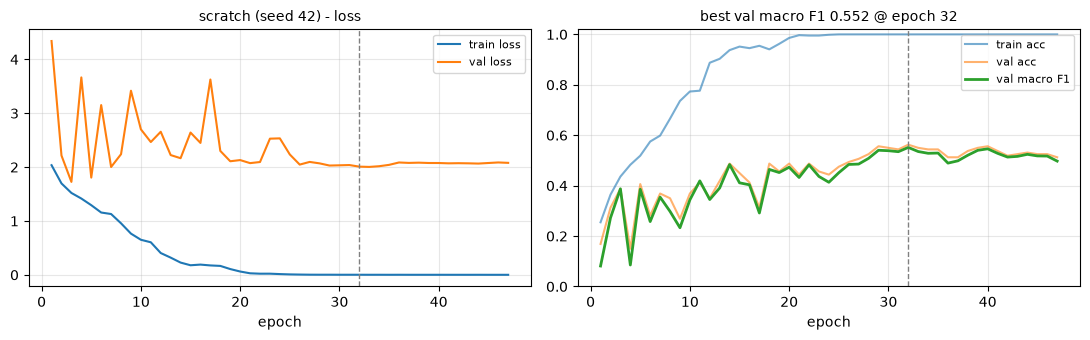

In [6]:
runs[("scratch", SEED)] = run_experiment("scratch", SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_history(runs[("scratch", SEED)][1], runs[("scratch", SEED)][2], axes)
plt.tight_layout()
plt.show()

**확인할 것** · Train loss는 계속 내려가는데 Val loss가 어느 시점부터 다시 오르나요? 그 시점이 과적합이 시작된 곳입니다. 최고 epoch와 중단 epoch를 기록하세요.

## 07 · Feature Extraction (분류기만 학습)

학습 후 **백본이 정말 그대로인지** 확인합니다. 새로 받은 ImageNet 가중치와 학습한 모델을 비교해, fc를 뺀 모든 값(가중치 + BN 기록장)이 완전히 같아야 합니다. BN 고정이 빠졌다면 여기서 running mean/var가 바뀐 것으로 잡힙니다.

[feature_extraction | seed 42] epoch   1 | train loss 1.723 acc 0.425 | val loss 1.261 acc 0.719 F1 0.701 | 4.0s ★
[feature_extraction | seed 42] epoch   2 | train loss 0.906 acc 0.841 | val loss 0.839 acc 0.775 F1 0.760 | 4.0s ★
[feature_extraction | seed 42] epoch   3 | train loss 0.604 acc 0.873 | val loss 0.668 acc 0.844 F1 0.843 | 3.9s ★
[feature_extraction | seed 42] epoch   4 | train loss 0.453 acc 0.916 | val loss 0.615 acc 0.838 F1 0.829 | 3.8s 
[feature_extraction | seed 42] epoch   5 | train loss 0.378 acc 0.930 | val loss 0.546 acc 0.850 F1 0.847 | 3.8s ★
[feature_extraction | seed 42] epoch   6 | train loss 0.331 acc 0.941 | val loss 0.524 acc 0.850 F1 0.847 | 3.9s ★
[feature_extraction | seed 42] epoch   7 | train loss 0.289 acc 0.945 | val loss 0.498 acc 0.856 F1 0.852 | 3.9s ★
[feature_extraction | seed 42] epoch   8 | train loss 0.258 acc 0.950 | val loss 0.472 acc 0.869 F1 0.865 | 3.9s ★
[feature_extraction | seed 42] epoch   9 | train loss 0.230 acc 0.958 | val loss 

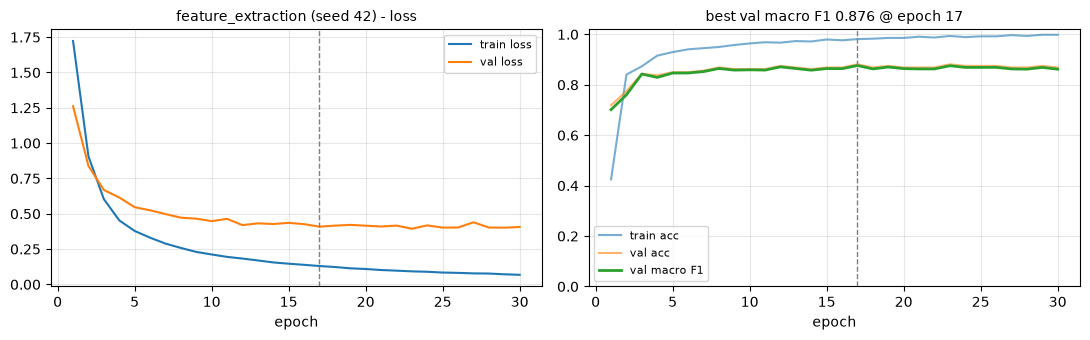

고정 대상 120개 중 바뀐 값: 0개 ✔


In [7]:
runs[("feature_extraction", SEED)] = run_experiment("feature_extraction", SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_history(runs[("feature_extraction", SEED)][1], runs[("feature_extraction", SEED)][2], axes)
plt.tight_layout()
plt.show()


def check_frozen(model, trainable_prefixes):
    """ImageNet 원본과 비교해, 학습 대상이 아닌 값이 하나도 바뀌지 않았는지 확인한다."""
    ref = resnet18(weights=WEIGHTS).state_dict()        # 원래 ImageNet 값
    now = {k: v.cpu() for k, v in model.state_dict().items()}
    frozen_keys = [k for k in ref if not k.startswith(trainable_prefixes)]
    changed = [k for k in frozen_keys if not torch.equal(ref[k], now[k])]
    trained_keys = [k for k in ref if k.startswith(trainable_prefixes) and k in now
                    and ref[k].shape == now[k].shape]
    trained_changed = [k for k in trained_keys if not torch.equal(ref[k], now[k])]
    print(f"고정 대상 {len(frozen_keys)}개 중 바뀐 값: {len(changed)}개", "✔" if not changed else "✘ 확인 필요")
    if changed:
        print("  바뀐 항목 예시:", changed[:5])
    if trained_keys:
        print(f"학습 대상 {len(trained_keys)}개 중 바뀐 값: {len(trained_changed)}개 (학습이 실제로 일어났는지)")


check_frozen(runs[("feature_extraction", SEED)][0], trainable_prefixes=("fc.",))

## 08 · Fine-tuning (layer4 + 분류기 학습)

ImageNet 가중치에서 바로 시작합니다(Feature Extraction 결과에서 이어가지 않음). 그래야 세 방식이 각자 독립적으로 출발해, 차이를 "학습 방식의 차이"로 설명할 수 있습니다. 학습 후 layer1~3은 그대로이고 layer4는 바뀌었는지 확인합니다.

[fine_tuning | seed 42] epoch   1 | train loss 1.103 acc 0.688 | val loss 0.567 acc 0.844 F1 0.840 | 4.1s ★
[fine_tuning | seed 42] epoch   2 | train loss 0.189 acc 0.961 | val loss 0.430 acc 0.856 F1 0.855 | 4.1s ★
[fine_tuning | seed 42] epoch   3 | train loss 0.068 acc 0.989 | val loss 0.396 acc 0.869 F1 0.867 | 4.0s ★
[fine_tuning | seed 42] epoch   4 | train loss 0.022 acc 1.000 | val loss 0.374 acc 0.881 F1 0.880 | 4.0s ★
[fine_tuning | seed 42] epoch   5 | train loss 0.016 acc 1.000 | val loss 0.376 acc 0.869 F1 0.867 | 4.0s 
[fine_tuning | seed 42] epoch   6 | train loss 0.013 acc 1.000 | val loss 0.372 acc 0.875 F1 0.871 | 4.0s 
[fine_tuning | seed 42] epoch   7 | train loss 0.007 acc 1.000 | val loss 0.381 acc 0.863 F1 0.860 | 4.0s 
[fine_tuning | seed 42] epoch   8 | train loss 0.005 acc 1.000 | val loss 0.373 acc 0.881 F1 0.878 | 4.0s 
[fine_tuning | seed 42] epoch   9 | train loss 0.005 acc 1.000 | val loss 0.378 acc 0.875 F1 0.871 | 4.0s 
[fine_tuning | seed 42] epoch  10

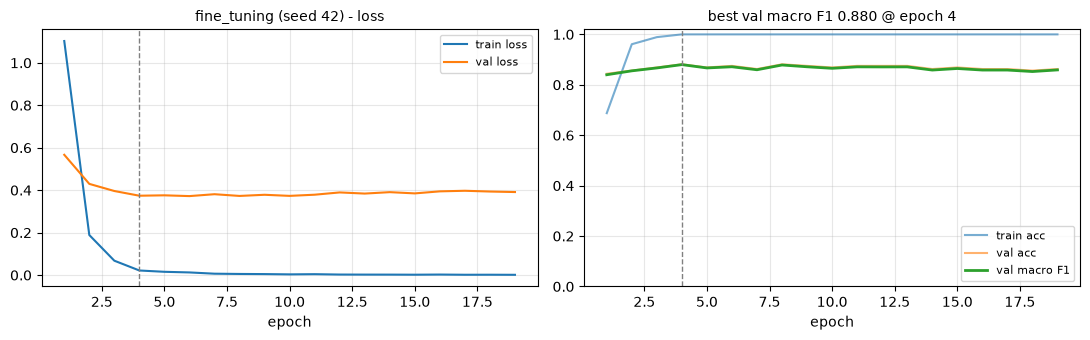

고정 대상 90개 중 바뀐 값: 0개 ✔
학습 대상 30개 중 바뀐 값: 30개 (학습이 실제로 일어났는지)


In [8]:
runs[("fine_tuning", SEED)] = run_experiment("fine_tuning", SEED)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
plot_history(runs[("fine_tuning", SEED)][1], runs[("fine_tuning", SEED)][2], axes)
plt.tight_layout()
plt.show()

check_frozen(runs[("fine_tuning", SEED)][0], trainable_prefixes=("layer4.", "fc."))

**확인할 것** · 07과 08에서 고정 대상의 바뀐 값이 모두 0개여야 합니다. Fine-tuning에서는 layer4 항목이 바뀌어 있어야 학습이 실제로 일어난 것입니다.

## 09 · 세 방식 비교 (seed 42)

보고서의 "세 방식의 설정과 결과", "학습 곡선과 학습 시간 비교"에 쓰는 표와 그림입니다. 학습 시간은 **학습+검증을 포함한 1회 실행 시간**이며, 최대 epoch와 중단 시점이 방식마다 다르므로 epoch당 시간도 함께 봅니다.

,방식,seed,학습 범위,학습률,전체 파라미터,학습 가능 파라미터,최대 epoch,최고 epoch,중단 epoch,총 시간(분),epoch당(초),Val Macro F1,Val Accuracy,Train Acc(최고 시점)
0,scratch,42,all,"{""all"": 0.001}","11,180,616","11,180,616",100,32,47,3.58,4.57,0.5516,0.5625,1.0000
1,feature_extraction,42,fc,"{""fc"": 0.001}","11,180,616","4,104",30,17,30,1.94,3.88,0.8765,0.8812,0.9812
2,fine_tuning,42,layer4+fc,"{""layer4"": 0.0001, ""fc"": 0.001}","11,180,616","8,397,832",30,4,19,1.27,4.01,0.8800,0.8812,1.0000


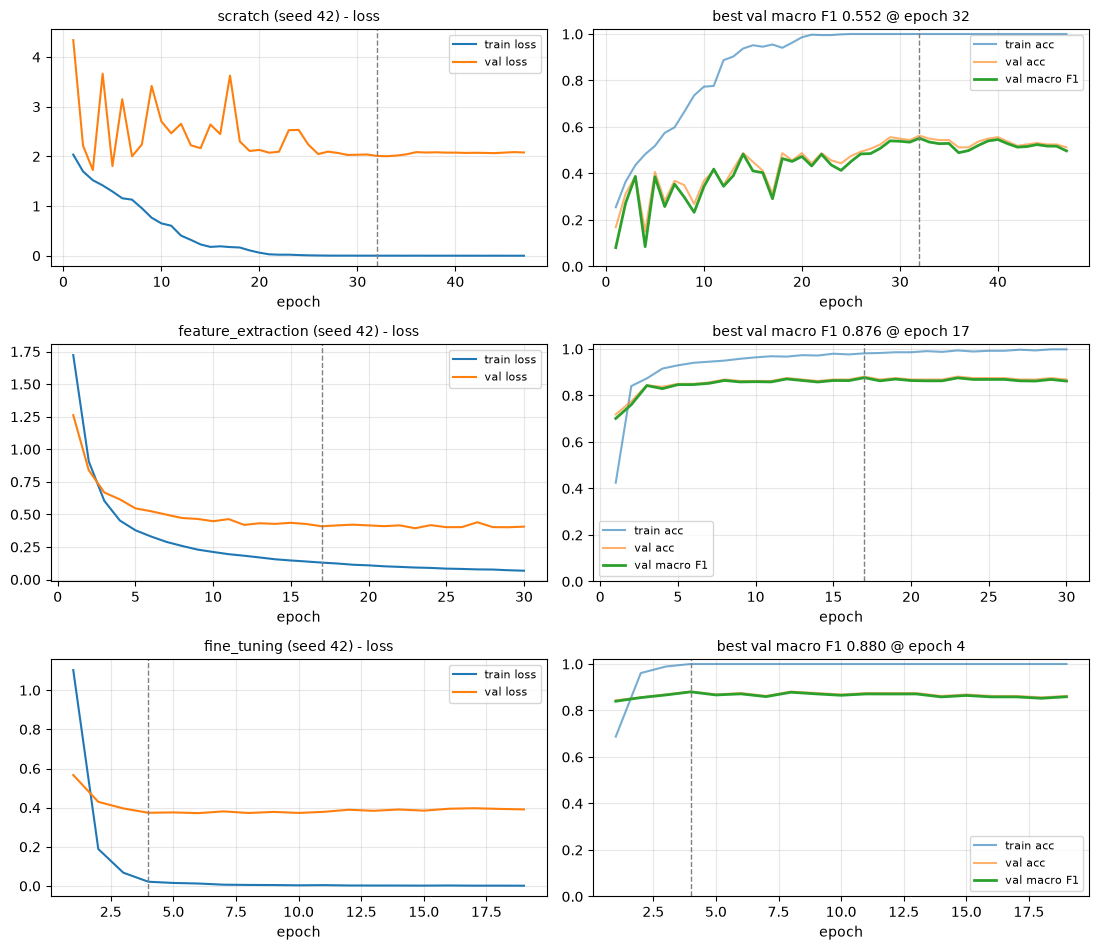

In [9]:
def comparison_table(summaries):
    rows = []
    for s in summaries:
        rows.append({
            "방식": s["experiment"], "seed": s["seed"],
            "학습 범위": s["train_scope"], "학습률": s["lr"],
            "전체 파라미터": f"{s['total_params']:,}", "학습 가능 파라미터": f"{s['trainable_params']:,}",
            "최대 epoch": s["max_epochs"], "최고 epoch": s["best_epoch"], "중단 epoch": s["stopped_epoch"],
            "총 시간(분)": round(s["total_time_sec"] / 60, 2), "epoch당(초)": s["mean_epoch_sec"],
            "Val Macro F1": s["best_val_macro_f1"], "Val Accuracy": s["best_val_accuracy"],
            "Train Acc(최고 시점)": s["best_train_accuracy"],
        })
    return pd.DataFrame(rows)


table42 = comparison_table([runs[(name, SEED)][2] for name in EXPERIMENTS])
table42.to_csv(RESULT_DIR / "baseline_comparison_seed42.csv", index=False, encoding="utf-8-sig")
display(table42)

# 학습 곡선 한 장에 모으기 (보고서용)
fig, axes = plt.subplots(len(EXPERIMENTS), 2, figsize=(11, 3.2 * len(EXPERIMENTS)))
for row, name in enumerate(EXPERIMENTS):
    _, hist, summary = runs[(name, SEED)]
    plot_history(hist, summary, axes[row])
plt.tight_layout()
plt.savefig(FIGURE_DIR / "10_learning_curves_seed42.png", dpi=120, bbox_inches="tight")
plt.show()

**확인할 것** · Train Acc(최고 시점)와 Val Accuracy의 차이가 클수록 과적합이 심하다는 뜻입니다. 세 방식에서 이 차이와 수렴 속도(최고 epoch)를 비교해 적어 두세요.

## 10 · Seed 반복 (42, 43, 44)

Val은 160장이라 1장 차이가 약 0.6%p입니다. 한 번의 결과로 우열을 정하지 않기 위해 Seed를 바꿔 반복하고 **평균 ± 표준편차**로 비교합니다. 이미 저장된 결과가 있으면 다시 학습하지 않고 불러옵니다(커널을 재시작했을 때 유용).

시간이 오래 걸리는 셀입니다. 09까지의 결과를 먼저 확인한 뒤 실행하세요.

[scratch | seed 43] Val Macro F1 0.5607 (epoch 33) | 3.7분
[scratch | seed 44] Val Macro F1 0.5111 (epoch 36) | 4.0분
[feature_extraction | seed 43] Val Macro F1 0.8821 (epoch 22) | 1.9분
[feature_extraction | seed 44] Val Macro F1 0.8906 (epoch 19) | 1.9분
[fine_tuning | seed 43] Val Macro F1 0.8844 (epoch 22) | 2.0분
[fine_tuning | seed 44] Val Macro F1 0.8978 (epoch 19) | 2.0분


,F1_평균,F1_표준편차,F1_최저,F1_최고,Acc_평균,최고epoch_평균,시간_평균_분
방식,,,,,,,
scratch,0.5411,0.0264,0.5111,0.5607,0.5479,33.6667,3.7667
feature_extraction,0.8831,0.0071,0.8765,0.8906,0.8875,19.3333,1.9400
fine_tuning,0.8874,0.0093,0.8800,0.8978,0.8896,15.0000,1.7600


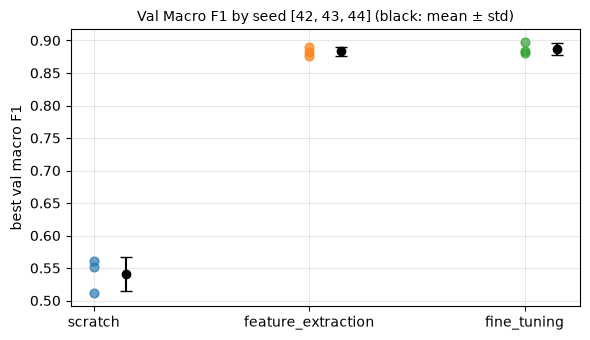

In [10]:
for name in EXPERIMENTS:
    for seed in SEEDS:
        if (name, seed) in runs:
            continue
        if (RESULT_DIR / f"summary_{name}_seed{seed}.json").exists():
            runs[(name, seed)] = load_run(name, seed, with_model=False)
            print(f"[{name} | seed {seed}] 저장된 결과를 불러왔습니다.")
            continue
        model, hist, summary = run_experiment(name, seed, verbose=False)
        print(f"[{name} | seed {seed}] Val Macro F1 {summary['best_val_macro_f1']:.4f} "
              f"(epoch {summary['best_epoch']}) | {summary['total_time_sec'] / 60:.1f}분")
        runs[(name, seed)] = (None, hist, summary)   # 메모리 절약: seed 42 외 모델은 보관하지 않음
        del model
        if device.type == "cuda":
            torch.cuda.empty_cache()

all_table = comparison_table([runs[(name, seed)][2] for name in EXPERIMENTS for seed in SEEDS])
all_table.to_csv(RESULT_DIR / "baseline_comparison_all_seeds.csv", index=False, encoding="utf-8-sig")

seed_summary = (all_table.groupby("방식", sort=False)
                .agg(F1_평균=("Val Macro F1", "mean"), F1_표준편차=("Val Macro F1", "std"),
                     F1_최저=("Val Macro F1", "min"), F1_최고=("Val Macro F1", "max"),
                     Acc_평균=("Val Accuracy", "mean"), 최고epoch_평균=("최고 epoch", "mean"),
                     시간_평균_분=("총 시간(분)", "mean"))
                .round(4))
seed_summary.to_csv(RESULT_DIR / "baseline_seed_summary.csv", encoding="utf-8-sig")
display(seed_summary)

# Seed별 점수를 점으로 찍어 흔들림을 눈으로 확인
fig, ax = plt.subplots(figsize=(6, 3.5))
for i, name in enumerate(EXPERIMENTS):
    scores = all_table.loc[all_table["방식"] == name, "Val Macro F1"]
    ax.scatter([i] * len(scores), scores, s=40, alpha=0.7)
    ax.errorbar(i + 0.15, scores.mean(), yerr=scores.std(), fmt="o", color="black", capsize=4)
ax.set_xticks(range(len(EXPERIMENTS)), list(EXPERIMENTS))
ax.set_ylabel("best val macro F1")
ax.set_title(f"Val Macro F1 by seed {SEEDS} (black: mean ± std)", fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "11_seed_variation.png", dpi=120, bbox_inches="tight")
plt.show()

**확인할 것** · 두 방식의 평균 차이가 각 방식의 표준편차보다 작다면 "차이가 있다"고 단정하기 어렵습니다. 보고서에는 평균과 표준편차를 함께 적습니다.

## 11 · Val 클래스별 성능과 Confusion Matrix (seed 42)

어떤 클래스를 잘 맞히고 어떤 클래스끼리 헷갈리는지 봅니다. Confusion Matrix의 **행은 실제 정답, 열은 모델 예측**입니다. Val은 클래스당 20장이라 1장이 클래스 Recall 5%p에 해당합니다.

여기서 보는 것은 모두 Validation입니다. Test는 아직 사용하지 않습니다.

,scratch,feature_extraction,fine_tuning
0 climbing (등반),0.821,0.952,0.976
1 jumping (점프),0.424,0.857,0.756
2 riding_a_bike (자전거 타기),0.732,0.930,0.927
3 riding_a_horse (승마),0.421,0.923,0.895
4 rowing_a_boat (보트 노 젓기),0.756,0.974,0.976
5 running (달리기),0.278,0.727,0.765
6 shooting_an_arrow (활쏘기),0.410,0.870,0.927
7 throwing_frisby (프리스비 던지기),0.571,0.778,0.821


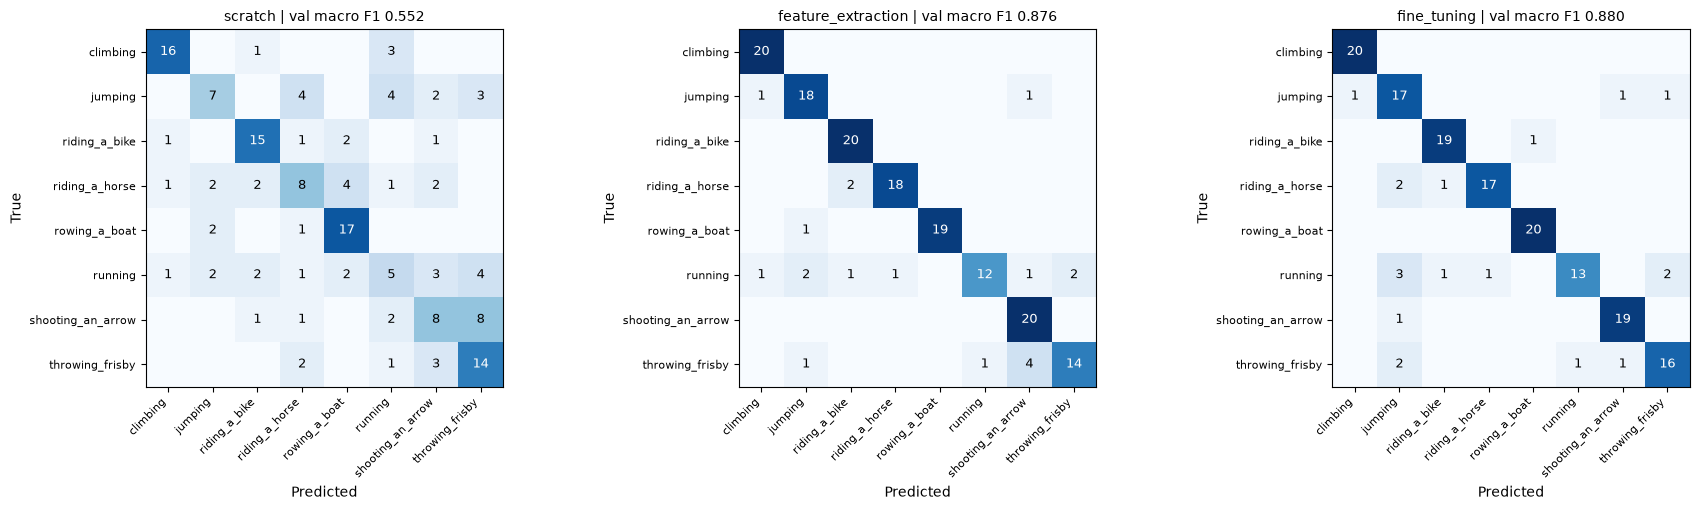

[scratch] 많이 헷갈린 쌍: shooting_an_arrow→throwing_frisby 8장, running→throwing_frisby 4장, riding_a_horse→rowing_a_boat 4장, jumping→running 4장, jumping→riding_a_horse 4장
[feature_extraction] 많이 헷갈린 쌍: throwing_frisby→shooting_an_arrow 4장, running→throwing_frisby 2장, running→jumping 2장, riding_a_horse→riding_a_bike 2장, throwing_frisby→running 1장
[fine_tuning] 많이 헷갈린 쌍: running→jumping 3장, throwing_frisby→jumping 2장, running→throwing_frisby 2장, riding_a_horse→jumping 2장, throwing_frisby→shooting_an_arrow 1장


In [11]:
val_results = {}   # 방식 → evaluate 결과
for name in EXPERIMENTS:
    model = runs[(name, SEED)][0]
    if model is None:                                     # 커널 재시작 등으로 모델이 없으면 저장본에서 불러옴
        model = load_run(name, SEED)[0]
        runs[(name, SEED)] = (model, *runs[(name, SEED)][1:])
    val_results[name] = evaluate(model, val_loader)

# 클래스별 F1 / Recall / Precision 표
per_class = {}
for name, r in val_results.items():
    rep = classification_report(r["y_true"], r["y_pred"], labels=list(range(NUM_CLASSES)),
                                target_names=class_names, output_dict=True, zero_division=0)
    for metric in ["f1-score", "recall", "precision"]:
        per_class[(metric, name)] = [rep[c][metric] for c in class_names]
per_class = pd.DataFrame(per_class, index=[f"{i} {en} ({ko})" for i, (en, ko)
                                           in enumerate(zip(class_names, class_names_ko))]).round(3)
per_class.to_csv(RESULT_DIR / "val_per_class_seed42.csv", encoding="utf-8-sig")
display(per_class["f1-score"])

# Confusion Matrix 세 개를 나란히
fig, axes = plt.subplots(1, len(EXPERIMENTS), figsize=(6 * len(EXPERIMENTS), 5.2))
for ax, (name, r) in zip(axes, val_results.items()):
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=list(range(NUM_CLASSES)))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=20)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                        color="white" if cm[i, j] > 10 else "black")
    ax.set_xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(NUM_CLASSES), class_names, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{name} | val macro F1 {r['macro_f1']:.3f}", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "12_val_confusion_seed42.png", dpi=120, bbox_inches="tight")
plt.show()

# 많이 헷갈린 (정답 → 예측) 쌍 상위 5개
for name, r in val_results.items():
    cm = confusion_matrix(r["y_true"], r["y_pred"], labels=list(range(NUM_CLASSES)))
    pairs = sorted([(cm[i, j], class_names[i], class_names[j])
                    for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0],
                   reverse=True)[:5]
    print(f"[{name}] 많이 헷갈린 쌍:", ", ".join(f"{t}→{p} {n}장" for n, t, p in pairs))

**확인할 것** · 01_eda에서 세운 가설(점프↔달리기 혼동, 프리스비의 작은 원반 누락)이 실제로 나타나나요? 세 방식 모두에서 나타나는 혼동과 Scratch에서만 나타나는 혼동을 구분해 적어 두세요.

## 12 · 틀린 Val 사진 보기와 내용 비율 점검

`ANALYZE`에 지정한 방식의 틀린 사진을 **모델이 실제로 본 모습(Padding 적용 후)**으로 보여줍니다. 기본값은 Seed 평균 Val Macro F1이 가장 높은 방식이며, 다른 방식을 보고 싶으면 이름을 바꾸면 됩니다.

또 02에서 저장한 `image_info.csv`의 `content_ratio`(Padding 후 224×224 중 실제 사진이 차지하는 비율)를 붙여, **길쭉해서 내용이 작아진 사진에서 더 많이 틀리는지** 확인합니다. Val 160장 기준이라 경향을 보는 정도로만 해석합니다.

분석 대상: fine_tuning
fine_tuning: Val 160장 중 19장 오분류


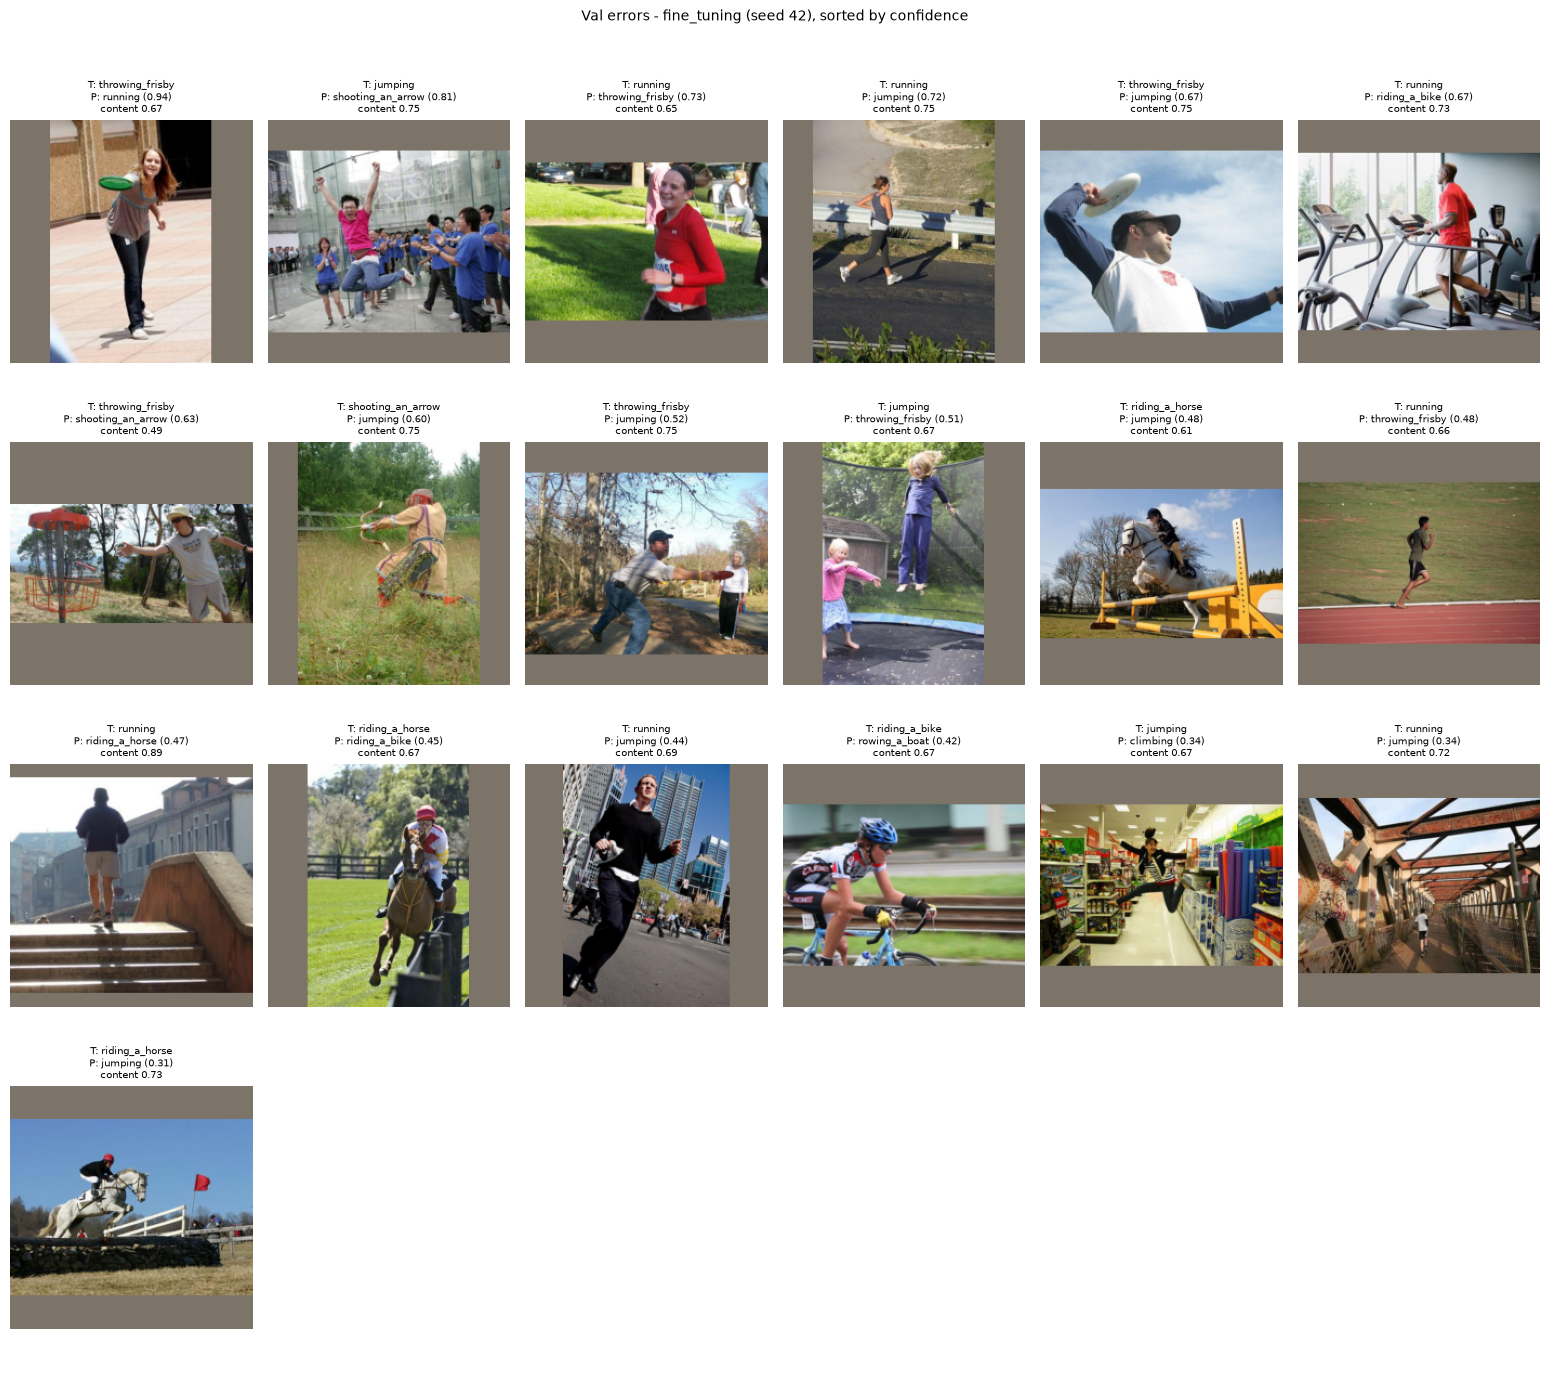

사진수                                    정답률  \
experiment       feature_extraction fine_tuning scratch feature_extraction   
content_group                                                                
<0.6 (매우 길쭉)                     10          10      10              0.900   
0.6~0.8                         125         125     125              0.864   
≥0.8 (정사각형에 가까움)                 25          25      25              0.960   

                                      
experiment       fine_tuning scratch  
content_group                         
<0.6 (매우 길쭉)           0.900    0.20  
0.6~0.8                0.864    0.56  
≥0.8 (정사각형에 가까움)       0.960    0.72

In [12]:
# 기본값: Seed 평균 Val Macro F1이 가장 높은 방식 (10번을 실행하지 않았다면 seed 42 기준)
score_source = seed_summary["F1_평균"] if "seed_summary" in globals() else table42.set_index("방식")["Val Macro F1"]
ANALYZE = score_source.idxmax()
print("분석 대상:", ANALYZE)

# 방식별 예측 결과를 사진 정보와 합치기
image_info = pd.read_csv(RESULT_DIR / "image_info.csv", encoding="utf-8-sig")[["image_id", "aspect_ratio", "content_ratio"]]
pred_rows = []
for name, r in val_results.items():
    frame = val_df[["image_id", "image_path", "target_id", "class_name"]].copy()
    frame["experiment"] = name
    frame["pred_id"] = r["y_pred"]
    frame["pred_name"] = [class_names[i] for i in r["y_pred"]]
    frame["confidence"] = r["probs"].max(axis=1).round(3)              # 예측한 클래스의 확률
    frame["true_prob"] = r["probs"][np.arange(len(frame)), frame["target_id"]].round(3)  # 정답 클래스 확률
    frame["correct"] = frame["pred_id"] == frame["target_id"]
    pred_rows.append(frame)
val_preds = pd.concat(pred_rows).merge(image_info, on="image_id", how="left")
val_preds.to_csv(RESULT_DIR / "val_predictions_seed42.csv", index=False, encoding="utf-8-sig")

# 틀린 사진 모아 보기 (확신하고 틀린 순서 = confidence 높은 순)
errors = val_preds[(val_preds["experiment"] == ANALYZE) & ~val_preds["correct"]].sort_values("confidence", ascending=False)
print(f"{ANALYZE}: Val {len(val_df)}장 중 {len(errors)}장 오분류")
show = errors.head(24)
n_cols = 6
n_rows = max(1, int(np.ceil(len(show) / n_cols)))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 3.4 * n_rows), squeeze=False)
pad = ResizePad(IMG_SIZE)
for ax in axes.flat:
    ax.axis("off")
for ax, row in zip(axes.flat, show.itertuples()):
    with Image.open(DATA_DIR / row.image_path) as img:
        ax.imshow(pad(img.convert("RGB")))           # 모델이 본 모습 그대로
    ax.set_title(f"T: {row.class_name}\nP: {row.pred_name} ({row.confidence:.2f})\n"
                 f"content {row.content_ratio:.2f}", fontsize=7)
plt.suptitle(f"Val errors - {ANALYZE} (seed {SEED}), sorted by confidence", fontsize=10, y=1.01)
plt.tight_layout()
plt.savefig(FIGURE_DIR / f"13_val_errors_{ANALYZE}_seed42.png", dpi=120, bbox_inches="tight")
plt.show()

# 내용 비율과 오분류의 관계
val_preds["content_group"] = pd.cut(val_preds["content_ratio"], bins=[0, 0.6, 0.8, 1.0],
                                    labels=["<0.6 (매우 길쭉)", "0.6~0.8", "≥0.8 (정사각형에 가까움)"])
ratio_table = (val_preds.groupby(["experiment", "content_group"], observed=False)["correct"]
               .agg(사진수="size", 정답률="mean").round(3).unstack("experiment"))
display(ratio_table)

**확인할 것** · 틀린 사진들에서 공통점이 보이나요? (사람이 작게 나옴, 도구가 안 보임, 배경이 비슷함 등) 확신(confidence)이 높은데 틀린 사진은 모델이 엉뚱한 단서를 강하게 믿고 있다는 신호일 수 있습니다. 내용 비율 그룹의 사진 수가 적으면 정답률 차이를 단정하지 마세요.

## 정리 (실행 후 채우기)

- seed 42 결과: `results/baseline_comparison_seed42.csv`, 학습 곡선 `figures/10_learning_curves_seed42.png`
- Seed 반복 결과: `results/baseline_seed_summary.csv`, `figures/11_seed_variation.png`
- Val 클래스별 성능·혼동: `results/val_per_class_seed42.csv`, `figures/12_val_confusion_seed42.png`
- 오분류 사진과 예측 기록: `figures/13_val_errors_*.png`, `results/val_predictions_seed42.csv`
- 다음 단계: 오분류 관찰에서 가설을 하나 골라 개선 실험 설계 (Test는 아직 사용하지 않음)